In [2]:
from pyspark.sql import SparkSession, functions as F

spark = (SparkSession.builder
         .master("local[*]")
         .appName("fraud")
         .getOrCreate())
print(spark.version)

c:\Users\Dell\OneDrive\Desktop\ClusterProject\.venv\Lib\site-packages\pyspark\testing\utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


4.3.0


In [3]:
from pyspark.sql.types import *

schema = StructType([
    StructField("transaction_id", IntegerType()),
    StructField("amount_usd", DoubleType()),
    StructField("merchant_category", StringType()),
    StructField("card_type", StringType()),
    StructField("auth_method", StringType()),
    StructField("channel", StringType()),
    StructField("device_type", StringType()),
    StructField("is_foreign_transaction", BooleanType()),
    StructField("hours_since_last_txn", DoubleType()),
    StructField("txn_count_last_24h", IntegerType()),
    StructField("distance_from_home_km", DoubleType()),
    StructField("card_age_months", IntegerType()),
    StructField("customer_age", IntegerType()),
    StructField("account_balance_usd", DoubleType()),
    StructField("is_new_merchant", BooleanType()),
    StructField("used_vpn", BooleanType()),
    StructField("ip_country_mismatch", BooleanType()),
    StructField("billing_shipping_mismatch", BooleanType()),
    StructField("cvv_retry_count", IntegerType()),
    StructField("velocity_score", DoubleType()),
    StructField("time_of_day_hour", IntegerType()),
    StructField("day_of_week", IntegerType()),
    StructField("is_ai_generated_scam_attempt", BooleanType()),
    StructField("merchant_risk_score", DoubleType()),
    StructField("prior_disputes", IntegerType()),
    StructField("is_fraud", IntegerType()),
])


In [4]:
df = spark.read.option("header", True).schema(schema).csv("../data/credit_card_fraud_2026.csv")
df.printSchema()
print(df.rdd.getNumPartitions())
print(df.count())
df.show(5)

root
 |-- transaction_id: integer (nullable = true)
 |-- amount_usd: double (nullable = true)
 |-- merchant_category: string (nullable = true)
 |-- card_type: string (nullable = true)
 |-- auth_method: string (nullable = true)
 |-- channel: string (nullable = true)
 |-- device_type: string (nullable = true)
 |-- is_foreign_transaction: boolean (nullable = true)
 |-- hours_since_last_txn: double (nullable = true)
 |-- txn_count_last_24h: integer (nullable = true)
 |-- distance_from_home_km: double (nullable = true)
 |-- card_age_months: integer (nullable = true)
 |-- customer_age: integer (nullable = true)
 |-- account_balance_usd: double (nullable = true)
 |-- is_new_merchant: boolean (nullable = true)
 |-- used_vpn: boolean (nullable = true)
 |-- ip_country_mismatch: boolean (nullable = true)
 |-- billing_shipping_mismatch: boolean (nullable = true)
 |-- cvv_retry_count: integer (nullable = true)
 |-- velocity_score: double (nullable = true)
 |-- time_of_day_hour: integer (nullable = 

In [5]:
df.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in df.columns]).show(vertical=True)


-RECORD 0---------------------------
 transaction_id               | 0   
 amount_usd                   | 0   
 merchant_category            | 0   
 card_type                    | 0   
 auth_method                  | 0   
 channel                      | 0   
 device_type                  | 0   
 is_foreign_transaction       | 0   
 hours_since_last_txn         | 0   
 txn_count_last_24h           | 0   
 distance_from_home_km        | 0   
 card_age_months              | 0   
 customer_age                 | 0   
 account_balance_usd          | 0   
 is_new_merchant              | 0   
 used_vpn                     | 0   
 ip_country_mismatch          | 0   
 billing_shipping_mismatch    | 0   
 cvv_retry_count              | 0   
 velocity_score               | 0   
 time_of_day_hour             | 0   
 day_of_week                  | 0   
 is_ai_generated_scam_attempt | 0   
 merchant_risk_score          | 0   
 prior_disputes               | 0   
 is_fraud                     | 0   



In [6]:

df.groupBy("is_fraud").count().show()
print(df.repartition(4).rdd.getNumPartitions())

+--------+-----+
|is_fraud|count|
+--------+-----+
|       1|  339|
|       0|19661|
+--------+-----+

4


In [7]:
df.describe("amount_usd", "customer_age", "account_balance_usd", "velocity_score").show()
df.select("merchant_category").distinct().show()
df.filter(F.col("customer_age") < 18).count()

+-------+------------------+-----------------+-------------------+------------------+
|summary|        amount_usd|     customer_age|account_balance_usd|    velocity_score|
+-------+------------------+-----------------+-------------------+------------------+
|  count|             20000|            20000|              20000|             20000|
|   mean|132.42459699999958|          49.6694| 3316.6625980000017|19.807735000000058|
| stddev| 256.9636655626206|18.49403160752827|  4350.720948381676|12.366300899609111|
|    min|               1.0|               18|              52.05|               0.0|
|    max|           6872.69|               81|          127125.86|              74.4|
+-------+------------------+-----------------+-------------------+------------------+

+-----------------+
|merchant_category|
+-----------------+
|           Gaming|
|    Online Retail|
|       Healthcare|
|        Groceries|
|           Travel|
|      Electronics|
|  Crypto Exchange|
|        Utilities|
|    

0

In [8]:
df.createOrReplaceTempView("txns")

spark.sql("""
    SELECT channel, COUNT(*) AS n, ROUND(AVG(amount_usd), 2) AS avg_amount
    FROM txns
    GROUP BY channel
    ORDER BY n DESC
""").show()

+-----------+----+----------+
|    channel|   n|avg_amount|
+-----------+----+----------+
|     Online|6810|    134.92|
|        POS|5191|    128.32|
|Contactless|3400|    131.31|
|     In-App|3225|    137.96|
|        ATM|1374|    125.36|
+-----------+----+----------+



In [9]:
def fraud_rate_by(col):
    return (df.groupBy(col)
              .agg(F.count("*").alias("n"),
                   F.sum("is_fraud").alias("frauds"),
                   F.round(F.avg("is_fraud") * 100, 2).alias("fraud_pct"))
              .orderBy(F.desc("fraud_pct")))

for c in ["merchant_category", "channel", "auth_method", "cvv_retry_count",
          "ip_country_mismatch", "is_ai_generated_scam_attempt", "is_foreign_transaction"]:
    print(c)
    fraud_rate_by(c).show()

merchant_category


+-----------------+----+------+---------+
|merchant_category|   n|frauds|fraud_pct|
+-----------------+----+------+---------+
|  Crypto Exchange| 561|    28|     4.99|
|       Gift Cards| 617|    27|     4.38|
|           Gaming|1036|    38|     3.67|
|      Electronics|2032|    48|     2.36|
|        Streaming|1010|    21|     2.08|
|        Utilities|1330|    25|     1.88|
|       Healthcare|1237|    16|     1.29|
|        Groceries|3242|    40|     1.23|
|             Fuel|1565|    19|     1.21|
|      Restaurants|2534|    29|     1.14|
|           Travel|1420|    16|     1.13|
|    Online Retail|3416|    32|     0.94|
+-----------------+----+------+---------+

channel
+-----------+----+------+---------+
|    channel|   n|frauds|fraud_pct|
+-----------+----+------+---------+
|     Online|6810|   135|     1.98|
|        ATM|1374|    25|     1.82|
|     In-App|3225|    52|     1.61|
|        POS|5191|    79|     1.52|
|Contactless|3400|    48|     1.41|
+-----------+----+------+------

In [10]:
(df.groupBy("is_fraud")
   .agg(F.count("*").alias("n"),
        F.round(F.avg("amount_usd"), 1).alias("avg_amount"),
        F.round(F.avg("velocity_score"), 1).alias("avg_velocity"),
        F.round(F.avg("merchant_risk_score"), 1).alias("avg_merchant_risk"),
        F.round(F.avg("distance_from_home_km"), 1).alias("avg_distance"),
        F.round(F.avg("hours_since_last_txn"), 1).alias("avg_hours_since_last"),
        F.round(F.avg("txn_count_last_24h"), 1).alias("avg_txn_24h"))
   .show())

+--------+-----+----------+------------+-----------------+------------+--------------------+-----------+
|is_fraud|    n|avg_amount|avg_velocity|avg_merchant_risk|avg_distance|avg_hours_since_last|avg_txn_24h|
+--------+-----+----------+------------+-----------------+------------+--------------------+-----------+
|       1|  339|     181.2|        29.0|             51.4|        21.4|                 7.0|        4.0|
|       0|19661|     131.6|        19.6|             37.2|        22.2|                 9.0|        3.2|
+--------+-----+----------+------------+-----------------+------------+--------------------+-----------+



In [11]:
fraud_rate_by("time_of_day_hour").orderBy("time_of_day_hour").show(24)

+----------------+---+------+---------+
|time_of_day_hour|  n|frauds|fraud_pct|
+----------------+---+------+---------+
|               0|808|    13|     1.61|
|               1|887|    20|     2.25|
|               2|814|    28|     3.44|
|               3|815|    23|     2.82|
|               4|826|    20|     2.42|
|               5|821|    33|     4.02|
|               6|840|     8|     0.95|
|               7|851|     9|     1.06|
|               8|785|     9|     1.15|
|               9|820|    10|     1.22|
|              10|824|    17|     2.06|
|              11|810|    18|     2.22|
|              12|840|     7|     0.83|
|              13|904|     7|     0.77|
|              14|815|    11|     1.35|
|              15|876|    11|     1.26|
|              16|789|    14|     1.77|
|              17|845|    15|     1.78|
|              18|794|     7|     0.88|
|              19|872|    12|     1.38|
|              20|865|    17|     1.97|
|              21|821|     9|      1.1|


In [12]:
def fraud_rate_by(col):
    return (df.groupBy(col)
              .agg(F.count("*").alias("n"),
                   F.sum("is_fraud").alias("frauds"),
                   F.round(F.avg("is_fraud") * 100, 2).alias("fraud_pct"))
              .orderBy(F.desc("fraud_pct")))

In [13]:
fraud_rate_by("cvv_retry_count").show()
fraud_rate_by("ip_country_mismatch").show()
fraud_rate_by("auth_method").show()


+---------------+-----+------+---------+
|cvv_retry_count|    n|frauds|fraud_pct|
+---------------+-----+------+---------+
|              2|  254|    41|    16.14|
|              3|   15|     2|    13.33|
|              1| 3073|   143|     4.65|
|              0|16658|   153|     0.92|
+---------------+-----+------+---------+

+-------------------+-----+------+---------+
|ip_country_mismatch|    n|frauds|fraud_pct|
+-------------------+-----+------+---------+
|               true| 1166|    91|      7.8|
|              false|18834|   248|     1.32|
+-------------------+-----+------+---------+

+-----------------+----+------+---------+
|      auth_method|   n|frauds|fraud_pct|
+-----------------+----+------+---------+
|No Authentication|2388|   106|     4.44|
|              OTP|4792|    75|     1.57|
|        3D Secure|5554|    86|     1.55|
|              PIN|4173|    48|     1.15|
|        Biometric|3093|    24|     0.78|
+-----------------+----+------+---------+



In [14]:
(df.groupBy("is_fraud")
   .agg(F.count("*").alias("n"),
        F.round(F.avg("amount_usd"), 1).alias("avg_amount"),
        F.round(F.avg("velocity_score"), 1).alias("avg_velocity"),
        F.round(F.avg("merchant_risk_score"), 1).alias("avg_merchant_risk"),
        F.round(F.avg("distance_from_home_km"), 1).alias("avg_distance"),
        F.round(F.avg("hours_since_last_txn"), 1).alias("avg_hours_since_last"),
        F.round(F.avg("txn_count_last_24h"), 1).alias("avg_txn_24h"))
   .show())

+--------+-----+----------+------------+-----------------+------------+--------------------+-----------+
|is_fraud|    n|avg_amount|avg_velocity|avg_merchant_risk|avg_distance|avg_hours_since_last|avg_txn_24h|
+--------+-----+----------+------------+-----------------+------------+--------------------+-----------+
|       1|  339|     181.2|        29.0|             51.4|        21.4|                 7.0|        4.0|
|       0|19661|     131.6|        19.6|             37.2|        22.2|                 9.0|        3.2|
+--------+-----+----------+------------+-----------------+------------+--------------------+-----------+



In [15]:
spark.sql("""
    SELECT merchant_category,
           COUNT(*) AS n,
           ROUND(AVG(is_fraud) * 100, 2) AS fraud_pct
    FROM txns
    GROUP BY merchant_category
    HAVING COUNT(*) >= 100
    ORDER BY fraud_pct DESC
""").show()

+-----------------+----+---------+
|merchant_category|   n|fraud_pct|
+-----------------+----+---------+
|  Crypto Exchange| 561|     4.99|
|       Gift Cards| 617|     4.38|
|           Gaming|1036|     3.67|
|      Electronics|2032|     2.36|
|        Streaming|1010|     2.08|
|        Utilities|1330|     1.88|
|       Healthcare|1237|     1.29|
|        Groceries|3242|     1.23|
|             Fuel|1565|     1.21|
|      Restaurants|2534|     1.14|
|           Travel|1420|     1.13|
|    Online Retail|3416|     0.94|
+-----------------+----+---------+



In [16]:
import os, time, math
import pandas as pd
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier, GBTClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.ml.functions import vector_to_array

SEED = 42
DATA_PATH = "../data/credit_card_fraud_2026.csv"
SCHEMA = schema                      

# ---------- features ----------
BOOL_COLS = ["is_foreign_transaction", "is_new_merchant", "used_vpn",
             "ip_country_mismatch", "billing_shipping_mismatch",
             "is_ai_generated_scam_attempt"]
CAT_COLS = ["merchant_category", "card_type", "auth_method", "channel", "device_type"]
NUM_COLS = ["amount_usd", "hours_since_last_txn", "txn_count_last_24h",
            "distance_from_home_km", "card_age_months", "customer_age",
            "account_balance_usd", "cvv_retry_count", "velocity_score",
            "time_of_day_hour", "day_of_week", "merchant_risk_score", "prior_disputes"]
ENGINEERED = ["risk_flags", "is_night", "amount_to_balance"]
BASE_FEATS = NUM_COLS + BOOL_COLS
ALL_FEATS = BASE_FEATS + ENGINEERED

def add_features(d):
    for c in BOOL_COLS:
        d = d.withColumn(c, F.col(c).cast("int"))
    return (d
            .withColumn("risk_flags", sum(F.col(c) for c in BOOL_COLS))
            .withColumn("is_night", (F.col("time_of_day_hour") < 6).cast("int"))
            .withColumn("amount_to_balance", F.col("amount_usd") / F.col("account_balance_usd")))

data = add_features(df)

fraud_rows = data.filter(F.col("is_fraud") == 1)
legit_rows = data.filter(F.col("is_fraud") == 0)
f_train, f_test = fraud_rows.randomSplit([0.8, 0.2], seed=SEED)
l_train, l_test = legit_rows.randomSplit([0.8, 0.2], seed=SEED)
train = f_train.union(l_train)
test = f_test.union(l_test).cache()

n_train = train.count()
n_pos = train.filter(F.col("is_fraud") == 1).count()
n_neg = n_train - n_pos
w_pos, w_neg = n_train / (2.0 * n_pos), n_train / (2.0 * n_neg)
train = train.withColumn("weight", F.when(F.col("is_fraud") == 1, F.lit(w_pos))
                                    .otherwise(F.lit(w_neg))).cache()
train.count()
n_test = test.count()
n_test_pos = test.filter(F.col("is_fraud") == 1).count()
print(f"train: {n_train} rows, {n_pos} fraud | test: {n_test} rows, {n_test_pos} fraud")
print(f"class weights: fraud={w_pos:.2f}, legitimate={w_neg:.2f}")

def build_pipeline(classifier, numeric_cols):
    indexers = [StringIndexer(inputCol=c, outputCol=c + "_idx", handleInvalid="keep") for c in CAT_COLS]
    encoder = OneHotEncoder(inputCols=[c + "_idx" for c in CAT_COLS],
                            outputCols=[c + "_ohe" for c in CAT_COLS])
    assembler = VectorAssembler(inputCols=numeric_cols + [c + "_ohe" for c in CAT_COLS],
                                outputCol="features")
    return Pipeline(stages=indexers + [encoder, assembler, classifier])

def evaluate(pred, k_pct=0.01):
    pr_auc = BinaryClassificationEvaluator(labelCol="is_fraud", rawPredictionCol="rawPrediction",
                                           metricName="areaUnderPR").evaluate(pred)
    roc_auc = BinaryClassificationEvaluator(labelCol="is_fraud", rawPredictionCol="rawPrediction",
                                            metricName="areaUnderROC").evaluate(pred)
    cm = {(r["is_fraud"], int(r["prediction"])): r["count"]
          for r in pred.groupBy("is_fraud", "prediction").count().collect()}
    tp, fp = cm.get((1, 1), 0), cm.get((0, 1), 0)
    fn, tn = cm.get((1, 0), 0), cm.get((0, 0), 0)
    precision = tp / (tp + fp) if (tp + fp) else 0.0
    recall = tp / (tp + fn) if (tp + fn) else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) else 0.0
    # business metric: review only the top 1% highest-scored transactions
    scored = pred.withColumn("p_fraud", vector_to_array("probability")[1])
    k = max(1, int(math.ceil(k_pct * (tp + fp + fn + tn))))
    caught = (scored.orderBy(F.desc("p_fraud")).limit(k)
                    .filter(F.col("is_fraud") == 1).count())
    return {"pr_auc": pr_auc, "roc_auc": roc_auc, "precision": precision, "recall": recall,
            "f1": f1, "recall_at_1pct": caught / (tp + fn) if (tp + fn) else 0.0,
            "precision_at_1pct": caught / k, "tp": tp, "fp": fp, "fn": fn, "tn": tn}

def run_experiment(name, make_classifier, numeric_cols):
    pipe = build_pipeline(make_classifier(), numeric_cols)
    t0 = time.time(); model = pipe.fit(train); fit_s = time.time() - t0
    t0 = time.time(); pred = model.transform(test).cache(); pred.count(); score_s = time.time() - t0
    metrics = evaluate(pred)
    pred.unpersist()
    metrics.update(name=name, fit_sec=round(fit_s, 2), score_sec=round(score_s, 2))
    return model, metrics

EXPERIMENTS = [
    ("LogReg (weighted)",
     lambda: LogisticRegression(labelCol="is_fraud", weightCol="weight", maxIter=50), ALL_FEATS),
    ("LogReg (no weights)",
     lambda: LogisticRegression(labelCol="is_fraud", maxIter=50), ALL_FEATS),
    ("RandomForest (weighted)",
     lambda: RandomForestClassifier(labelCol="is_fraud", weightCol="weight",
                                    numTrees=100, maxDepth=8, seed=SEED), ALL_FEATS),
    ("RandomForest (weighted, base features only)",
     lambda: RandomForestClassifier(labelCol="is_fraud", weightCol="weight",
                                    numTrees=100, maxDepth=8, seed=SEED), BASE_FEATS),
    ("GBT (weighted)",
     lambda: GBTClassifier(labelCol="is_fraud", weightCol="weight",
                           maxIter=50, maxDepth=5, seed=SEED), ALL_FEATS),
]

rows, models = [], {}
for name, make_clf, feats in EXPERIMENTS:
    try:
        model, metrics = run_experiment(name, make_clf, feats)
        models[name] = model
        rows.append(metrics)
        print("done:", name)
    except Exception as e:           
        print("FAILED:", name, "->", str(e)[:300])

print(f"\nrandom-model PR-AUC baseline = fraud share in test = {n_test_pos / n_test:.3f}")
cols = ["name", "pr_auc", "roc_auc", "precision", "recall", "f1", "recall_at_1pct",
        "precision_at_1pct", "tp", "fp", "fn", "tn", "fit_sec", "score_sec"]
results = pd.DataFrame(rows)[cols].round(3)
display(results)


rf_name = "RandomForest (weighted)"
rf_model = models[rf_name]
meta = rf_model.transform(test).schema["features"].metadata["ml_attr"]["attrs"]
names = {a["idx"]: a["name"] for group in meta.values() for a in group}
imps = rf_model.stages[-1].featureImportances.toArray()
top = sorted(((names.get(i, f"feature_{i}"), float(v)) for i, v in enumerate(imps)),
             key=lambda x: -x[1])[:15]
importance_df = pd.DataFrame(top, columns=["feature", "importance"]).round(4)
print(importance_df.to_string(index=False))

train: 16069 rows, 287 fraud | test: 3931 rows, 52 fraud
class weights: fraud=27.99, legitimate=0.51
done: LogReg (weighted)
done: LogReg (no weights)
done: RandomForest (weighted)
done: RandomForest (weighted, base features only)
done: GBT (weighted)

random-model PR-AUC baseline = fraud share in test = 0.013


,name,pr_auc,roc_auc,precision,recall,f1,recall_at_1pct,precision_at_1pct,tp,fp,fn,tn,fit_sec,score_sec
0,LogReg (weighted),0.386,0.954,0.091,0.865,0.164,0.346,0.450,45,451,7,3428,42.69,2.00
1,LogReg (no weights),0.395,0.958,0.560,0.269,0.364,0.327,0.425,14,11,38,3868,22.91,2.49
2,RandomForest (weighted),0.275,0.923,0.201,0.538,0.293,0.288,0.375,28,111,24,3768,61.14,3.47
3,"RandomForest (weighted, base features only)",0.229,0.905,0.182,0.462,0.261,0.308,0.400,24,108,28,3771,27.03,7.06
4,GBT (weighted),0.196,0.895,0.117,0.673,0.200,0.231,0.300,35,263,17,3616,87.87,4.24


                          feature  importance
                       risk_flags      0.1871
                  cvv_retry_count      0.1274
              merchant_risk_score      0.1012
                   velocity_score      0.0898
              ip_country_mismatch      0.0437
auth_method_ohe_No Authentication      0.0383
             hours_since_last_txn      0.0307
                  is_new_merchant      0.0257
                 time_of_day_hour      0.0256
               txn_count_last_24h      0.0249
                  card_age_months      0.0232
                     customer_age      0.0225
           is_foreign_transaction      0.0222
        billing_shipping_mismatch      0.0202
                amount_to_balance      0.0194


,cores,rows,fit_sec,score_sec
0,4,20000,18.6,0.4
1,4,100000,22.1,0.6
2,4,200000,25.5,1.0


,cores,rows,fit_sec,score_sec,speedup_vs_1_core
0,1,100000,21.5,0.5,1.00
1,2,100000,15.4,0.5,1.40
2,4,100000,16.8,0.4,1.28


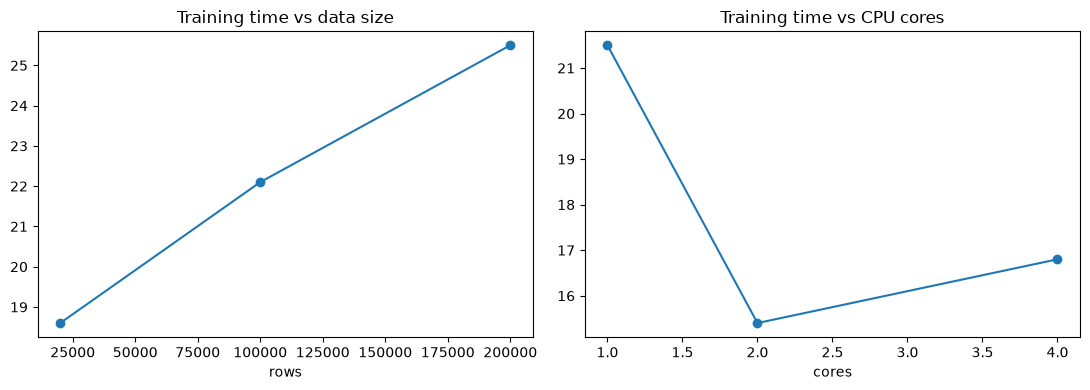

In [17]:
import matplotlib.pyplot as plt

QUICK = True                         
SIZE_FACTORS = [1, 5, 10] if QUICK else [1, 5, 10, 25]
CORE_COUNTS = [c for c in (1, 2, 4, 8) if c <= (os.cpu_count() or 1)]
CORE_TEST_FACTOR = 5 if QUICK else 10

def get_spark(master="local[*]"):
    return (SparkSession.builder.master(master).appName("fraud-detection")
            .config("spark.driver.memory", "4g")
            .config("spark.sql.shuffle.partitions", "8").getOrCreate())

def timing_run(cores, factor):
    global spark
    spark.stop()
    spark = get_spark("local[*]" if cores is None else f"local[{cores}]")
    base = spark.read.option("header", True).schema(SCHEMA).csv(DATA_PATH)
    big = base.crossJoin(spark.range(factor)).drop("id") if factor > 1 else base
    big = add_features(big).repartition(8).cache()
    n = big.count()                                   
    pipe = build_pipeline(RandomForestClassifier(labelCol="is_fraud", numTrees=20,
                                                 maxDepth=6, seed=SEED), ALL_FEATS)
    t0 = time.time(); model = pipe.fit(big); fit_s = time.time() - t0
    t0 = time.time(); model.transform(big).count(); score_s = time.time() - t0
    return {"cores": cores or os.cpu_count(), "rows": n,
            "fit_sec": round(fit_s, 1), "score_sec": round(score_s, 1)}

size_df = pd.DataFrame([timing_run(None, f) for f in SIZE_FACTORS])
core_df = pd.DataFrame([timing_run(c, CORE_TEST_FACTOR) for c in CORE_COUNTS])
core_df["speedup_vs_1_core"] = (core_df["fit_sec"].iloc[0] / core_df["fit_sec"]).round(2)
display(size_df); display(core_df)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
size_df.plot(x="rows", y="fit_sec", marker="o", ax=axes[0], legend=False, title="Training time vs data size")
core_df.plot(x="cores", y="fit_sec", marker="o", ax=axes[1], legend=False, title="Training time vs CPU cores")
plt.tight_layout(); plt.show()